# LAB 06 — Bài 18: Attention Distribution

## Mục tiêu
Tính attention score và attention weight cho từng token trong câu, sau đó hiển thị bảng và biểu đồ phân phối.

## Câu thực hành
> The movie was surprisingly good despite a very slow beginning.

Mỗi token được gán một key vector giả lập; query cũng là vector giả lập. Các vector được tạo cố định bằng seed để có thể chạy lại và thu cùng một kết quả. Scores dùng dot product chia cho `sqrt(d_k)`, sau đó chuẩn hóa bằng softmax ổn định số.

,Token,Score,Attention
0,The,-0.212991,0.066017
1,movie,0.773652,0.177070
2,was,0.393482,0.121071
3,surprisingly,0.484942,0.132666
4,good,0.607872,0.150020
5,despite,-0.039892,0.078493
6,a,0.256895,0.105614
7,very,-0.369226,0.056468
8,slow,-0.133643,0.071468
9,beginning,-0.686569,0.041113


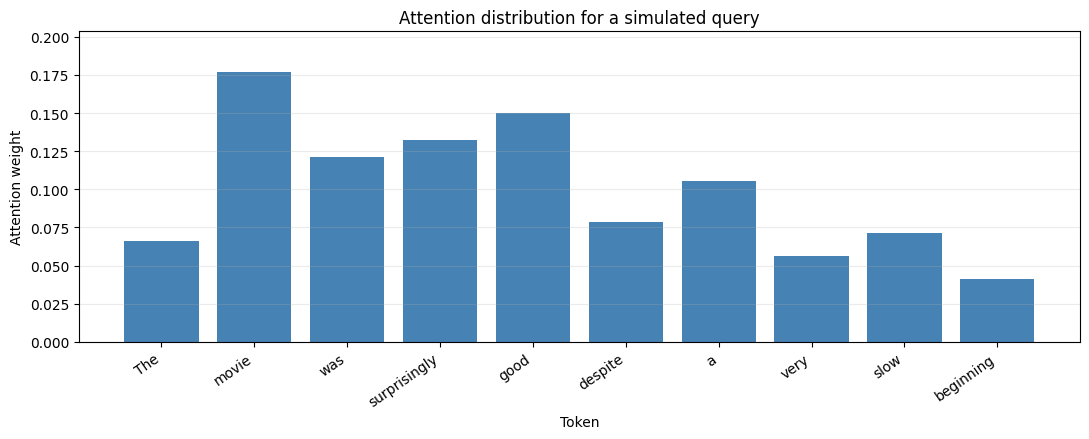

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Token sequence from the lab
tokens = [
    "The", "movie", "was", "surprisingly", "good",
    "despite", "a", "very", "slow", "beginning"
]

# Simulated query and reproducible key vectors
query = np.array([0.8, -0.3, 0.2, 0.5], dtype=np.float64)
rng = np.random.default_rng(seed=18)
keys = rng.normal(size=(len(tokens), query.size))
d_k = keys.shape[1]

# Scaled dot-product scores
scores = (keys @ query) / np.sqrt(d_k)

# Numerically stable softmax
def stable_softmax(x):
    x = np.asarray(x, dtype=np.float64)
    shifted = x - np.max(x)
    exp_x = np.exp(shifted)
    return exp_x / exp_x.sum()

attention_weights = stable_softmax(scores)

# Table requested in the exercise
results = pd.DataFrame({
    "Token": tokens,
    "Score": scores,
    "Attention": attention_weights,
})
display(results.round(6))

# Attention distribution plot
plt.figure(figsize=(11, 4.5))
plt.bar(tokens, attention_weights, color="steelblue")
plt.xlabel("Token")
plt.ylabel("Attention weight")
plt.title("Attention distribution for a simulated query")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, max(attention_weights) * 1.15)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()